<a href="https://colab.research.google.com/github/tranduchoa518-lang/fake-news-detection/blob/main/notebooks/06_cnn_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
!pip install -q pandas numpy scikit-learn matplotlib tensorflow

In [14]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import drive
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, Conv1D, GlobalMaxPooling1D,
    Dense, Dropout
)

drive.mount('/content/drive')

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [15]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [16]:
import os

print("Các thư mục trong MyDrive:")

for item in os.listdir("/content/drive/MyDrive"):
    print(item)

Các thư mục trong MyDrive:
devcpp.exe
LabanKey
note_content
d4064ae5ff9ed8584a9824df264e6563.jpg
received_638655517153406.jpeg
received_467703264990478.jpeg
received_314220130392565.jpeg
received_266252718730992.jpeg
received_1262801834186406.jpeg
IMG_20220302_193308.jpg
1649247922775..jpg
Classroom
20240906_083502 (1).jpg
20240906_083502.jpg
Untitled1.cpp
Untitled5.cpp
Hòa Trần - Bài tập thực hành số 1. (1).gdoc
Hòa Trần - Bài tập thực hành số 1. (1).gslides
Hòa Trần - Bài tập thực hành số 1..gslides
Hòa Trần - Bài tập thực hành số 1..gdoc
Bài tập thực hành số 2.gdoc
bài 4 vs 3.cpp
20241001_190851.jpg
bài 16 vs 3 (1).cpp
bài 16 vs 3.cpp
bài 18 vs 3 (1).cpp
bài 18 vs 3.cpp
bài 17 vs 3 (1).cpp
bài 17 vs 3.cpp
bài 19 vs 3 (1).cpp
bài 19 vs 3.cpp
bài 20 vs 3 (1).cpp
bài 20 vs 3.cpp
bài 21 vs 3 (3).cpp
bài 21 vs 3 (2).cpp
bài 21 vs 3 (1).cpp
bài 21 vs 3.cpp
drive-download-20240916T170119Z-001.zip
CoreJava(TiengViet).pdf
thi

In [17]:
import os

root = "/content/drive/MyDrive"

for folder, subfolders, files in os.walk(root):
    for file in files:
        if file in ["train.csv", "val.csv", "test.csv"]:
            print(os.path.join(folder, file))

/content/drive/MyDrive/fake-news-detection/data/processed/train.csv
/content/drive/MyDrive/fake-news-detection/data/processed/val.csv
/content/drive/MyDrive/fake-news-detection/data/processed/test.csv


In [18]:
import os

path = "/content/drive/MyDrive"

print("Drive tồn tại:", os.path.exists(path))
print("Nội dung MyDrive:")

print(os.listdir(path))

Drive tồn tại: True
Nội dung MyDrive:
['devcpp.exe', 'LabanKey', 'note_content', 'd4064ae5ff9ed8584a9824df264e6563.jpg', 'received_638655517153406.jpeg', 'received_467703264990478.jpeg', 'received_314220130392565.jpeg', 'received_266252718730992.jpeg', 'received_1262801834186406.jpeg', 'IMG_20220302_193308.jpg', '1649247922775..jpg', 'Classroom', '20240906_083502 (1).jpg', '20240906_083502.jpg', 'Untitled1.cpp', 'Untitled5.cpp', 'Hòa Trần - Bài tập thực hành số 1. (1).gdoc', 'Hòa Trần - Bài tập thực hành số 1. (1).gslides', 'Hòa Trần - Bài tập thực hành số 1..gslides', 'Hòa Trần - Bài tập thực hành số 1..gdoc', 'Bài tập thực hành số 2.gdoc', 'bài 4 vs 3.cpp', '20241001_190851.jpg', 'bài 16 vs 3 (1).cpp', 'bài 16 vs 3.cpp', 'bài 18 vs 3 (1).cpp', 'bài 18 vs 3.cpp', 'bài 17 vs 3 (1).cpp', 'bài 17 vs 3.cpp', 'bài 19 vs 3 (1).cpp', 'bài 19 vs 3.cpp', 'bài 20 vs 3 (1).cpp', 'bài 20 vs 3.cpp', 'bài 21 vs 3 (3).cpp', 'bài 21 vs 

In [19]:
import os

for path in [
    "/content/drive/MyDrive/fake-news-detection",
    "/content/drive/MyDrive/fake-news-detection/data",
    "/content/drive/MyDrive/fake-news-detection/data/processed"
]:
    print("\n", path)
    print("Tồn tại:", os.path.exists(path))

    if os.path.exists(path):
        print("Các tệp:", os.listdir(path))


 /content/drive/MyDrive/fake-news-detection
Tồn tại: True
Các tệp: ['data', 'results']

 /content/drive/MyDrive/fake-news-detection/data
Tồn tại: True
Các tệp: ['processed']

 /content/drive/MyDrive/fake-news-detection/data/processed
Tồn tại: True
Các tệp: ['train.csv', 'val.csv', 'test.csv']


In [20]:
DATA_DIR = "/content/drive/MyDrive/fake-news-detection/data/processed"

train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
val_df = pd.read_csv(os.path.join(DATA_DIR, "val.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print(train_df.head())

Train: (50493, 2)
Validation: (10820, 2)
Test: (10821, 2)
                                                text  label
0  THE FACE OF THE DEMOCRAT PARTY Has A Message F...      1
1  INCOMING FRESHMEN Are Put On Notice With Welco...      1
2  REPUBLICANS CALL FOR ANSWERS: Did Wasserman-Sc...      1
3  EXTORTION? HOW IRAN Used Nuke Deal To Force Ob...      1
4  Democrats want strong response to intel report...      0


In [21]:
MAX_WORDS = 30000
MAX_LEN = 300

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(train_df["text"])

X_train = pad_sequences(
    tokenizer.texts_to_sequences(train_df["text"]),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val = pad_sequences(
    tokenizer.texts_to_sequences(val_df["text"]),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    tokenizer.texts_to_sequences(test_df["text"]),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

y_train = train_df["label"].values
y_val = val_df["label"].values
y_test = test_df["label"].values

vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)

print("Kích thước từ điển:", vocab_size)
print("X_train:", X_train.shape)

Kích thước từ điển: 30000
X_train: (50493, 300)


In [22]:
model = Sequential([
    Embedding(vocab_size, 128, input_length=MAX_LEN),

    Conv1D(128, 5, activation="relu"),
    GlobalMaxPooling1D(),

    Dense(64, activation="relu"),
    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [23]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=64,
    verbose=1
)

Epoch 1/5
789/789 ━━━━━━━━━━━━━━━━━━━━ 235s 296ms/step - accuracy: 0.9466 - loss: 0.1280 - val_accuracy: 0.9810 - val_loss: 0.0518
Epoch 2/5
789/789 ━━━━━━━━━━━━━━━━━━━━ 234s 297ms/step - accuracy: 0.9924 - loss: 0.0237 - val_accuracy: 0.9823 - val_loss: 0.0556
Epoch 3/5
789/789 ━━━━━━━━━━━━━━━━━━━━ 234s 296ms/step - accuracy: 0.9991 - loss: 0.0041 - val_accuracy: 0.9823 - val_loss: 0.0642
Epoch 4/5
789/789 ━━━━━━━━━━━━━━━━━━━━ 270s 307ms/step - accuracy: 0.9994 - loss: 0.0020 - val_accuracy: 0.9812 - val_loss: 0.0815
Epoch 5/5
789/789 ━━━━━━━━━━━━━━━━━━━━ 233s 295ms/step - accuracy: 0.9995 - loss: 0.0020 - val_accuracy: 0.9781 - val_loss: 0.0993


In [24]:
y_prob = model.predict(X_test).ravel()
y_pred = (y_prob >= 0.5).astype(int)

results = {
    "Model": "CNN",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0)
}

print(pd.DataFrame([results]))
print(classification_report(y_test, y_pred))

339/339 ━━━━━━━━━━━━━━━━━━━━ 11s 33ms/step
  Model  Accuracy  Precision    Recall  F1-score
0   CNN  0.976527   0.962557  0.992993  0.977538
              precision    recall  f1-score   support

           0       0.99      0.96      0.98      5255
           1       0.96      0.99      0.98      5566

    accuracy                           0.98     10821
   macro avg       0.98      0.98      0.98     10821
weighted avg       0.98      0.98      0.98     10821



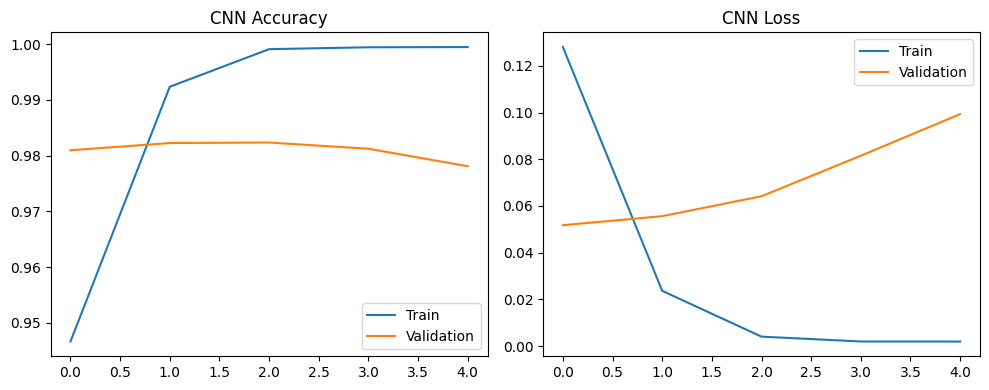

Đã lưu mô hình CNN và kết quả!


In [25]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("CNN Loss")
plt.legend()

plt.tight_layout()
plt.show()

os.makedirs("results", exist_ok=True)

model.save("results/cnn_model.keras")

with open("results/cnn_metrics.json", "w") as f:
    json.dump(results, f, indent=4)

print("Đã lưu mô hình CNN và kết quả!")

In [26]:
SAVE_DIR = "/content/drive/MyDrive/fake-news-detection/results"

os.makedirs(SAVE_DIR, exist_ok=True)

with open(f"{SAVE_DIR}/cnn_metrics.json", "w") as f:
    json.dump(results, f, indent=4)